# DATA-445: In-Class Assignment 17

**1.** Consider the `customers.csv` datafile. This file contains information related to customers' activity on a company website. Below are the description of the variables.

- `ID:` customer ID
- `Visit_Time:` The number of visits to the company's website in a given month.
- `Average_Expense:` The average amount of money that the customer has spend.
- `Sex:` gender of the customer (0: female, 1: male).
- `Age:` age of the customer.

**In Python**, answer the following:

**(a)** (3 points) Using the `pandas` library, read the csv file and create a data-frame called `customers`.

In [1]:
import pandas as pd

customers = pd.read_csv("customers.csv")
customers.head()


,ID,Visit_Time,Average_Expense,Sex,Age
0,1,3,5.7,0,10
1,2,5,14.5,0,27
2,3,16,33.5,0,32
3,4,5,15.9,0,30
4,5,16,24.9,0,23


**(b)** (3 points) Using the appropriate Python commands, remove the `ID` variable.

In [2]:
customers = customers.drop(columns=['ID'])
customers.head()

,Visit_Time,Average_Expense,Sex,Age
0,3,5.7,0,10
1,5,14.5,0,27
2,16,33.5,0,32
3,5,15.9,0,30
4,16,24.9,0,23


**(c)** (5 points) Using the appropriate standardization formula, put all the variables on the same scale. *Hint:* Notice that `Sex` is a 0-1 variable.

In [3]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

customers[["Visit_Time", "Average_Expense", "Age"]] = scaler.fit_transform(customers[["Visit_Time", "Average_Expense", "Age"]])
customers.head()

,Visit_Time,Average_Expense,Sex,Age
0,0.117647,0.041096,0,0.051282
1,0.235294,0.342466,0,0.487179
2,0.882353,0.993151,0,0.615385
3,0.235294,0.390411,0,0.564103
4,0.882353,0.698630,0,0.384615


**(d)** (8 points) Using the silhouette score, estimate the number of cluster for this dataset. Consider 2 to 20 clusters. Make sure to use `n_init=20`.

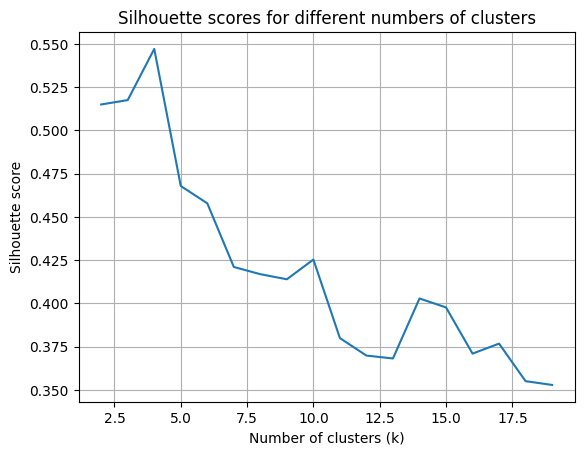

[np.float64(0.5149508485218993), np.float64(0.5174842528512758), np.float64(0.5470352055273493), np.float64(0.46786240589427425), np.float64(0.45785098918856776), np.float64(0.42108283954543085), np.float64(0.4169184376123824), np.float64(0.4139783923792474), np.float64(0.4253700064298094), np.float64(0.37998385757539666), np.float64(0.3699044245833875), np.float64(0.36824600339133706), np.float64(0.40289264008363546), np.float64(0.39772539267058105), np.float64(0.37103705951958194), np.float64(0.376821361434359), np.float64(0.3551193040092044), np.float64(0.3529584346046641)]


In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sil_scores = []
for k in range(2, 20):
    kmeans = KMeans(n_clusters=k, n_init=20, random_state=42)
    kmeans.fit(customers)
    sil_scores.append(silhouette_score(customers, kmeans.labels_))

import matplotlib.pyplot as plt

plt.plot(range(2, 20), sil_scores)
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Silhouette scores for different numbers of clusters")
plt.grid(True)
plt.show()

print(sil_scores)

From the above, 4 clusters maximizes the sil score

**(e)** (6 points) Using the `cmeans` function from the `skfuzzy.cluster` library, cluster the customers into the number of clusters estimated from part (d).

In [5]:
from skfuzzy.cluster import cmeans

#fiting fuzzy c-means clustering
fc, W, u0, d, jm, p, pc = cmeans(customers.T, c=4, m=1.25, error=0.001, maxiter=1000, seed=42)

In [7]:
W.shape

(4, 60)

In [9]:
W[0]

array([1.15120912e-03, 2.15566185e-05, 4.79208094e-02, 5.42085285e-05,
       2.02668142e-03, 1.55438702e-04, 3.96223254e-03, 1.28494389e-04,
       1.75329829e-05, 1.14629919e-03, 2.79688142e-04, 1.18702363e-04,
       3.96223254e-03, 3.99871248e-07, 1.42241040e-04, 4.01785214e-04,
       1.94875170e-04, 6.36377148e-09, 4.29056433e-03, 9.69171867e-01,
       3.53774950e-07, 9.83756250e-01, 1.02231382e-10, 9.90953543e-01,
       9.99977625e-01, 1.35359492e-09, 3.21340009e-06, 9.99662917e-01,
       7.77845417e-06, 2.75270196e-07, 9.42998140e-05, 9.99996702e-01,
       9.99998386e-01, 9.94413704e-01, 2.75270196e-07, 9.10593800e-07,
       9.99465331e-01, 9.34498423e-05, 2.57149914e-06, 3.53774950e-07,
       3.67991911e-09, 1.31321745e-06, 3.76643975e-08, 5.24012658e-05,
       9.99576185e-01, 9.99662917e-01, 3.53797334e-02, 3.79024880e-06,
       1.05935924e-07, 9.90953543e-01, 9.44990715e-11, 7.10108870e-01,
       9.99208147e-01, 1.95102054e-06, 4.87924991e-03, 3.83475729e-08,
      

**(f)** (10 points) Change the likelihoods to cluster labels using 70% as threshold. Describe each of the clusters from part (d).

In [10]:
import numpy as np

customers["Cluster"] = np.nan

#changing likelihoods to labels
customers["Cluster"] = np.where(W[0] > 0.7, 0, customers["Cluster"])
customers["Cluster"] = np.where(W[1] > 0.7, 1, customers["Cluster"])
customers["Cluster"] = np.where(W[2] > 0.7, 2, customers["Cluster"])
customers["Cluster"] = np.where(W[3] > 0.7, 3, customers["Cluster"])

customers["Cluster"].value_counts(normalize=True)

Cluster
3.0    0.316667
0.0    0.266667
1.0    0.250000
2.0    0.166667
Name: proportion, dtype: float64